# Weather Patterns around Utrecht Centraal: Baseline and Snowstorm Event 

Data was obtained from the KNMI hourly observations, station 260 (De Bilt) and included weather data from 2021 to 2026. 

For the typical (baseline) weather at Utrecht Centraal during the research period, KNMI data was filtered on the dates: January 1st to January 15th for the years 2021 to 2025. 

The following five weather indicators were chosen and analysed:
- Temperature
- Dew point
- Precipitation
- Wind speed
- Snow occurence

Given the relatively small sample years to determine the baseline, the mininimum and maximum value were also displayed along with the average for each of the abovementioned weather indicators.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----- Settings -------------------------------------------------------------------------------
WEATHER_CSV = None            # None = auto-detect; or give the full path: Path(r"C:\...\weather_total_cleaned.csv")
STATION = 260                 # KNMI De Bilt
BASELINE_YEARS = list(range(2021, 2026))
EVENT_YEAR = 2026
WINDOW_START, WINDOW_END = (1, 1), (1, 15)     # (month, day), both inclusive

# Thresholds for the "share of hours" panel in figure 1
FROST_C, WET_MM, HEAVY_MM, GUST_KMH = 0.0, 0.1, 2.0, 50.0

# Look
C_BASE, C_EVENT = "gray", "tab:red"
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})

# Labels for the days of the window (a non-leap year is used only to build the labels)
N_DAYS = (pd.Timestamp(2001, *WINDOW_END) - pd.Timestamp(2001, *WINDOW_START)).days + 1
DAY_LABELS = [(pd.Timestamp(2001, *WINDOW_START) + pd.Timedelta(days=i)).strftime("%d %b") for i in range(N_DAYS)]
WINDOW_TEXT = f"{DAY_LABELS[0]}–{DAY_LABELS[-1]}"
BASE_TEXT = f"{BASELINE_YEARS[0]}–{BASELINE_YEARS[-1]}"

In [2]:
# ----- 1. Read the KNMI file -------------------------------------------------------------------
def find_file(explicit, names=("weather_total_cleaned.csv", "weather_selected.csv")):
    """Use the given path, or look in the current folder, ./data, ../data and ../../data."""
    if explicit is not None:
        return Path(explicit)
    here = Path.cwd()
    for folder in [here, here / "data", here.parent / "data", here.parent, here.parent.parent / "data"]:
        for name in names:
            if (folder / name).is_file():
                return folder / name
    raise FileNotFoundError(f"Weather file not found (running from {here}). Set WEATHER_CSV in the settings cell.")


raw = pd.read_csv(find_file(WEATHER_CSV), skipinitialspace=True)
raw.columns = raw.columns.str.replace("#", "", regex=False).str.strip()
raw = raw[raw["STN"] == STATION]

# ----- 2. Process dates/hours and convert KNMI units -------------------------------------------
# HH is hour-ending in UTC (1..24), so HH - 1 is the start of the hour.
# Conversions go into NEW columns, so re-running a cell can never convert twice.
start_of_day = pd.to_datetime(raw["YYYYMMDD"].astype(str), format="%Y%m%d")
wx = pd.DataFrame(index=pd.DatetimeIndex(start_of_day + pd.to_timedelta(raw["HH"] - 1, unit="h"), name="datetime"))
wx["temp_c"] = raw["T"].to_numpy() / 10                                           # 0.1 degC -> degC
wx["dew_c"] = raw["TD"].to_numpy() / 10                                           # 0.1 degC -> degC
wx["precip_mm"] = np.where(raw["RH"].to_numpy() == -1, 0, raw["RH"].to_numpy() / 10)   # 0.1 mm -> mm, -1 = trace -> 0
wx["wind_kmh"] = raw["FH"].to_numpy() * 0.1 * 3.6                                 # hourly mean wind, 0.1 m/s -> km/h
wx["gust_kmh"] = raw["FX"].to_numpy() * 0.1 * 3.6                                 # highest gust, 0.1 m/s -> km/h
wx["snow"] = raw["S"].to_numpy() == 1                                             # snow indicator
wx["humidity_pct"] = raw["U"].to_numpy()                                          # relative humidity, %
wx["pressure_hpa"] = raw["P"].to_numpy() / 10                                     # 0.1 hPa -> hPa
wx = wx.sort_index()

In [3]:
# ----- 3. Select 1-15 January of every year ---------------------------------------------------
def get_window(year):
    start = pd.Timestamp(year, *WINDOW_START)
    end = pd.Timestamp(year, *WINDOW_END) + pd.Timedelta(days=1)       # exclusive upper bound
    f = wx[(wx.index >= start) & (wx.index < end)].copy()
    f["wday"] = (f.index.normalize() - start).days                     # 0 = first day of the window
    return f


windows = {y: get_window(y) for y in BASELINE_YEARS + [EVENT_YEAR]}

# ----- 4. Weather indicators --------------------------------------------------------------------
def daily_table(f):
    """One row per day: used to compare the days of 2026 with the same calendar days of the baseline."""
    g = f.groupby("wday")
    return pd.DataFrame({
        "temp_mean": g["temp_c"].mean(),
        "dew_mean": g["dew_c"].mean(),
        "precip_mm": g["precip_mm"].sum(),
        "wind_mean": g["wind_kmh"].mean(),
        "snow_hours": g["snow"].sum(),
    })


def yearly_indicators(f):
    """One value per indicator for a whole window (one year)."""
    return pd.Series({
        "temp_mean": f["temp_c"].mean(),
        "temp_min": f["temp_c"].min(),
        "precip_total": f["precip_mm"].sum(),
        "wind_mean": f["wind_kmh"].mean(),
        "gust_max": f["gust_kmh"].max(),
        "snow_hours": f["snow"].sum(),
        "humidity_mean": f["humidity_pct"].mean(),
        "pressure_mean": f["pressure_hpa"].mean(),
        "frost_hours": (f["temp_c"] < FROST_C).sum(),
        "wet_hours": (f["precip_mm"] >= WET_MM).sum(),
        "heavy_hours": (f["precip_mm"] >= HEAVY_MM).sum(),
        "gust_hours": (f["gust_kmh"] >= GUST_KMH).sum(),
    }, dtype=float)


daily_all = pd.concat({y: daily_table(f) for y, f in windows.items()}, names=["year", "wday"])   # rows: (year, day)
yearly = pd.DataFrame({y: yearly_indicators(f) for y, f in windows.items()}).T                   # rows: year
base_years = yearly.loc[BASELINE_YEARS]                                                          # baseline years only

In [4]:
# ----- Plot helpers -----------------------------------------------------------------------------
def style_days(ax):
    ax.set_xticks(range(N_DAYS))
    ax.set_xticklabels(DAY_LABELS, rotation=60, ha="right", fontsize=8)


def band_panel(ax, metric, title, ylabel, with_event=False, zero_line=False):
    """Daily baseline mean with a min-max band across the baseline years (+ the event year if requested)."""
    piv = daily_all[metric].unstack("year")
    base = piv[BASELINE_YEARS]
    x = base.index
    if not with_event:                                   # thin lines show the individual baseline years
        for y in BASELINE_YEARS:
            ax.plot(x, base[y], color=C_BASE, lw=0.8, alpha=0.6)
    ax.fill_between(x, base.min(axis=1), base.max(axis=1), color=C_BASE, alpha=0.25, label="Baseline range (min-max)")
    ax.plot(x, base.mean(axis=1), color="dimgray", lw=2.5, label=f"Baseline mean {BASE_TEXT}")
    if with_event:
        ax.plot(x, piv[EVENT_YEAR], color=C_EVENT, lw=2.5, marker="o", ms=4, label=str(EVENT_YEAR))
    if zero_line:
        ax.axhline(0, color="black", lw=0.8)
    ax.set_title(title, loc="left")
    ax.set_ylabel(ylabel)
    style_days(ax)


def bar_panel(ax, metric, title, ylabel, with_event=False):
    """Daily baseline mean bars (whiskers = min-max across years), with event-year bars next to them if requested."""
    piv = daily_all[metric].unstack("year")
    base = piv[BASELINE_YEARS]
    x = np.asarray(base.index, dtype=float)
    mean = base.mean(axis=1)
    err = [(mean - base.min(axis=1)).to_numpy(), (base.max(axis=1) - mean).to_numpy()]
    w = 0.4 if with_event else 0.7
    shift = w / 2 if with_event else 0
    ax.bar(x - shift, mean, width=w, color="lightgray", edgecolor="gray", yerr=err, capsize=2,
           error_kw={"lw": 0.8, "ecolor": "dimgray"}, label="Baseline mean (whiskers = min-max)")
    if with_event:
        ax.bar(x + shift, piv[EVENT_YEAR], width=w, color=C_EVENT, label=str(EVENT_YEAR))
    ax.set_title(title, loc="left")
    ax.set_ylabel(ylabel)
    style_days(ax)

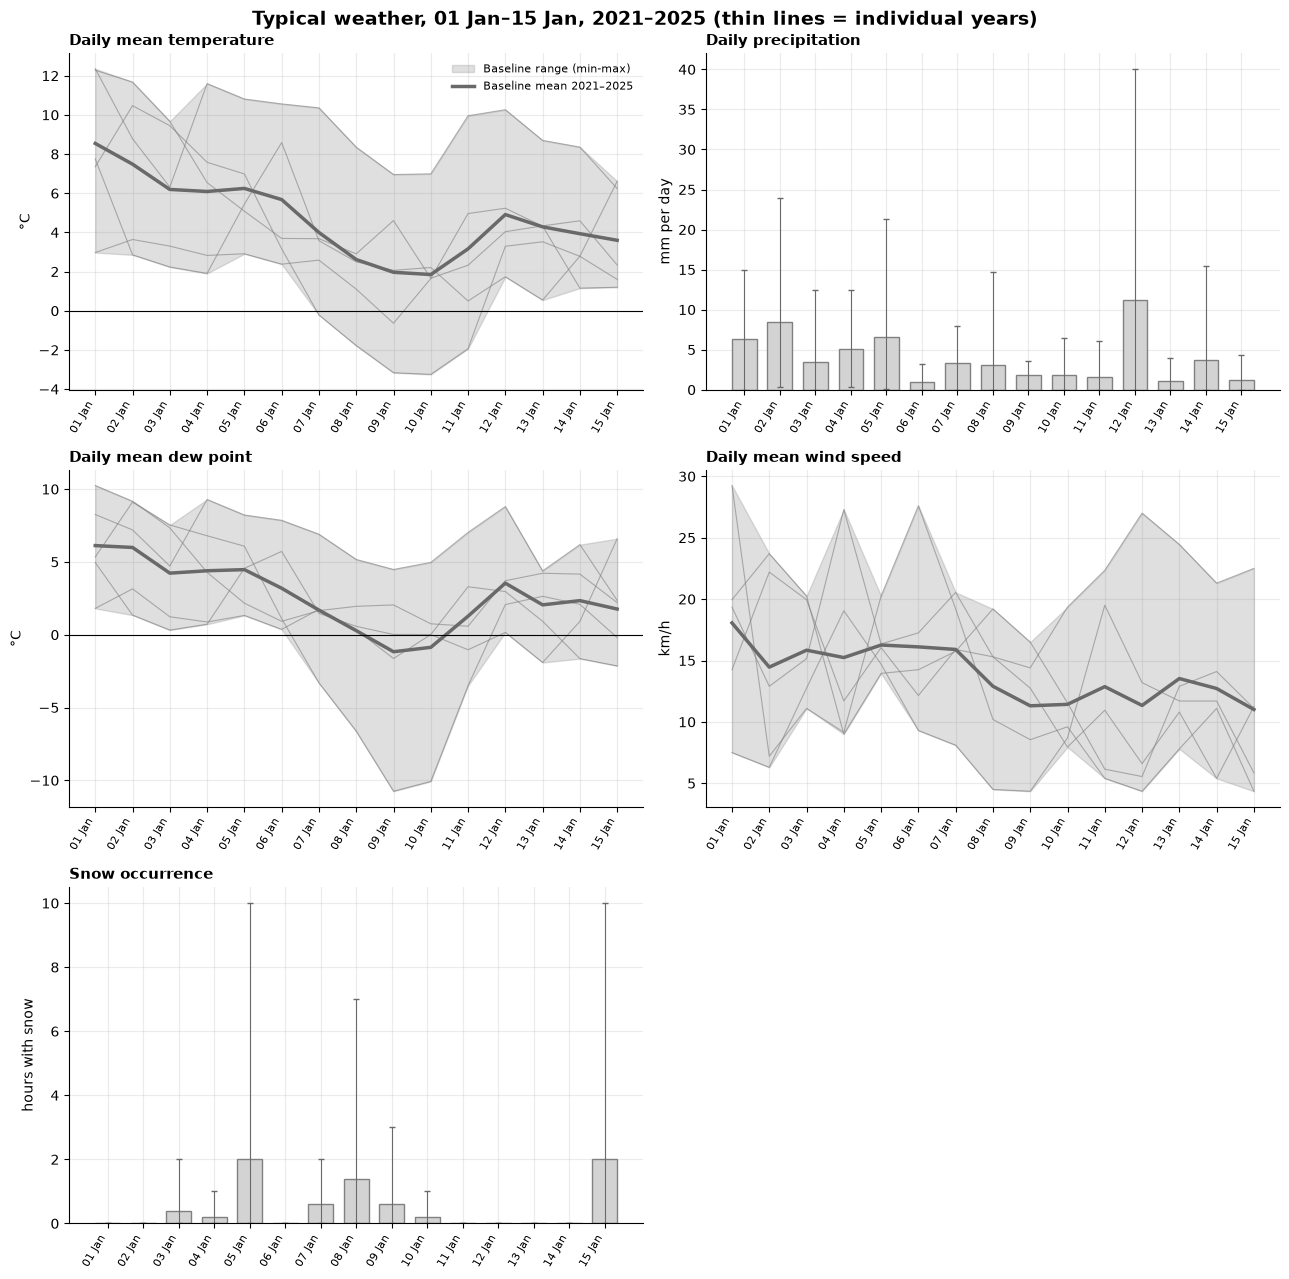

In [5]:
# ----- Figure 1: typical weather (baseline only) ---------------------------------------------

fig, axes = plt.subplots(3, 2, figsize=(13, 13))

# 1. Temperature
band_panel(
    axes[0, 0], "temp_mean",
    "Daily mean temperature", "°C",
    zero_line=True
)

# 2. Precipitation
bar_panel(
    axes[0, 1], "precip_mm",
    "Daily precipitation", "mm per day"
)

# 3. Dew point
band_panel(
    axes[1, 0], "dew_mean",
    "Daily mean dew point", "°C",
    zero_line=True
)

# 4. Wind speed
band_panel(
    axes[1, 1], "wind_mean",
    "Daily mean wind speed", "km/h"
)

# 5. Snow occurrence
bar_panel(
    axes[2, 0], "snow_hours",
    "Snow occurrence", "hours with snow"
)

# Hide unused sixth panel
axes[2, 1].set_visible(False)

axes[0, 0].legend(frameon=False, fontsize=8)

fig.suptitle(
    f"Typical weather, {WINDOW_TEXT}, {BASE_TEXT} (thin lines = individual years)",
    fontsize=14,
    fontweight="bold"
)

fig.tight_layout()
plt.show()

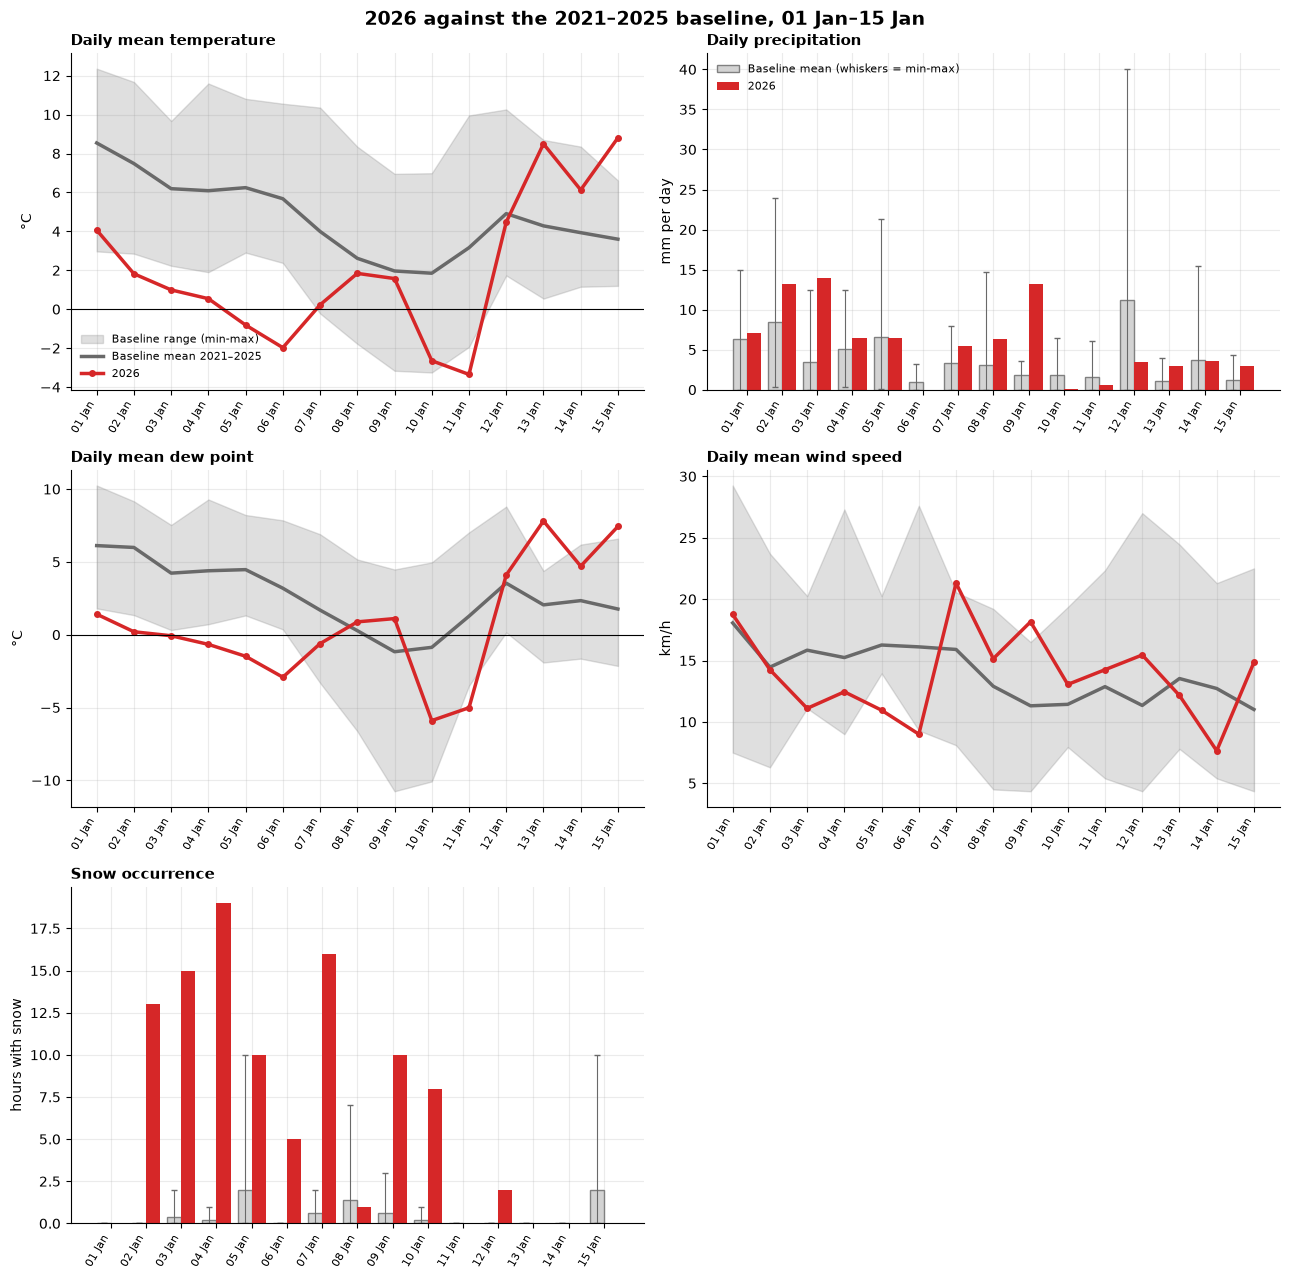

In [6]:
# ----- Figure 2: the event year against the baseline -----------------------------------------

fig, axes = plt.subplots(3, 2, figsize=(13, 13))

# 1. Temperature
band_panel(
    axes[0, 0], "temp_mean",
    "Daily mean temperature", "°C",
    with_event=True, zero_line=True
)

# 2. Precipitation
bar_panel(
    axes[0, 1], "precip_mm",
    "Daily precipitation", "mm per day",
    with_event=True
)

# 3. Dew point
band_panel(
    axes[1, 0], "dew_mean",
    "Daily mean dew point", "°C",
    with_event=True, zero_line=True
)

# 4. Wind speed
band_panel(
    axes[1, 1], "wind_mean",
    "Daily mean wind speed", "km/h",
    with_event=True
)

# 5. Snow occurrence
bar_panel(
    axes[2, 0], "snow_hours",
    "Snow occurrence", "hours with snow",
    with_event=True
)

# Hide unused sixth panel
axes[2, 1].set_visible(False)

axes[0, 0].legend(frameon=False, fontsize=8)
axes[0, 1].legend(frameon=False, fontsize=8)

fig.suptitle(
    f"{EVENT_YEAR} against the {BASE_TEXT} baseline, {WINDOW_TEXT}",
    fontsize=14,
    fontweight="bold"
)

fig.tight_layout()
plt.show()

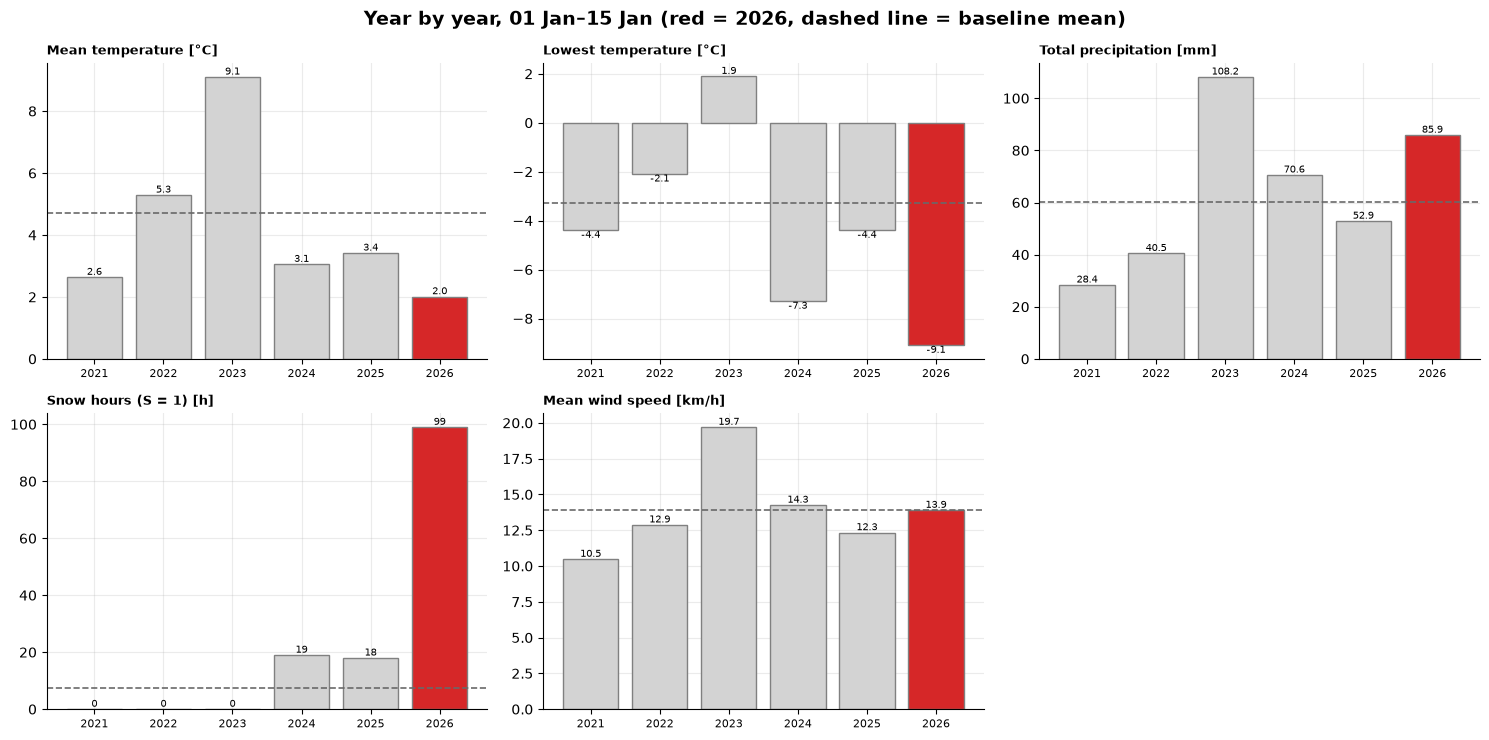

In [7]:
# ----- Figure 3: year by year -------------------------------------------------------------------

PANELS = [
    ("temp_mean", "Mean temperature", "°C", 1, False),
    ("temp_min", "Lowest temperature", "°C", 1, False),
    ("precip_total", "Total precipitation", "mm", 1, False),
    ("snow_hours", "Snow hours (S = 1)", "h", 0, False),
    ("wind_mean", "Mean wind speed", "km/h", 1, False),
]

years_all = list(yearly.index)
year_labels = [str(y) for y in years_all]

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))

for ax, (key, name, unit, dec, dots) in zip(axes.ravel(), PANELS):
    vals = yearly[key]
    title = f"{name} [{unit}]"

    if dots:
        ax.scatter(year_labels, vals, s=80, zorder=3,
                   color=[C_EVENT if y == EVENT_YEAR else "gray" for y in years_all])
        pad = (vals.max() - vals.min()) * 0.3 + 0.3
        ax.set_ylim(vals.min() - pad, vals.max() + pad)

        for lab, v in zip(year_labels, vals):
            ax.annotate(f"{v:.{dec}f}", (lab, v),
                        textcoords="offset points", xytext=(0, 8),
                        ha="center", fontsize=7)
    else:
        bars = ax.bar(
            year_labels, vals,
            edgecolor="gray",
            color=[C_EVENT if y == EVENT_YEAR else "lightgray" for y in years_all]
        )

        for bar, v in zip(bars, vals):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height(),
                f"{v:.{dec}f}",
                ha="center",
                va="bottom" if v >= 0 else "top",
                fontsize=7
            )

    ax.axhline(base_years[key].mean(), color="dimgray", ls="--", lw=1.2)
    ax.set_title(title, loc="left", fontsize=9)
    ax.tick_params(axis="x", labelsize=8)

axes.ravel()[5].set_visible(False)

fig.suptitle(
    f"Year by year, {WINDOW_TEXT} (red = {EVENT_YEAR}, dashed line = baseline mean)",
    fontsize=14,
    fontweight="bold"
)

fig.tight_layout()
plt.show()